# 📊 Analisis Model untuk Prediksi Penjualan Bulanan per Item

**Tujuan:** Menganalisis 3 model Machine Learning (Random Forest, XGBoost, dan Stacking Ensemble) untuk menemukan model terbaik dalam memprediksi penjualan bulanan. Model terbaik ini nantinya dapat digunakan sebagai dasar untuk perencanaan stok.

**Dataset:** Predict Future Sales (Kaggle)

**Alur Kerja:**
1.  **Eksplorasi Data (EDA):** Memahami data melalui statistik dan visualisasi.
2.  **Pra-pemrosesan:** Membersihkan dan mempersiapkan data.
3.  **Agregasi & Feature Engineering:** Mengubah data harian menjadi bulanan per item dan membuat fitur prediktif.
4.  **Pemodelan & Evaluasi:** Melatih dan membandingkan 3 model untuk menemukan yang terbaik.

### Langkah 0: Import Library yang Dibutuhkan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from itertools import product

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')
sns.set(style='whitegrid')

### Langkah 1: Memuat Data

In [ ]:
# Memuat semua file data yang relevan
sales = pd.read_csv('sales_train.csv')
items = pd.read_csv('items.csv')
item_cats = pd.read_csv('item_categories.csv')
shops = pd.read_csv('shops.csv')
test = pd.read_csv('test.csv')

### Langkah 1B: Eksplorasi Data (EDA - Exploratory Data Analysis)

Di bagian ini, kita akan memeriksa data lebih dalam untuk mendapatkan wawasan awal.

In [ ]:
print("--- Informasi Data Penjualan (sales) ---")
print("Bentuk Data (Shape):", sales.shape)
print("\nInfo Data:")
sales.info()
print("\nStatistik Deskriptif:")
print(sales.describe())

--- Informasi Data Penjualan (sales) ---
Bentuk Data (Shape): (2935849, 6)

Info Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2935849 entries, 0 to 2935848
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   date            object 
 1   date_block_num  int64  
 2   shop_id         int64  
 3   item_id         int64  
 4   item_price      float64
 5   item_cnt_day    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 134.4+ MB

Statistik Deskriptif:
       date_block_num       shop_id       item_id    item_price  item_cnt_day
count    2.935849e+06  2.935849e+06  2.935849e+06  2.935849e+06  2.935849e+06
mean     1.456991e+01  3.300173e+01  1.019723e+04  8.908532e+02  1.242641e+00
std      9.422988e+00  1.622697e+01  6.324297e+03  1.729800e+03  2.618834e+00
min      0.000000e+00  0.000000e+00  0.000000e+00 -1.000000e+00 -2.200000e+01
25%      7.000000e+00  2.200000e+01  4.476000e+03  2.490000e+02  1.000000e+00
50%      1.400

In [ ]:
print("--- Informasi Data Barang (items) ---")
print("Bentuk Data (Shape):", items.shape)
print("\nInfo Data:")
items.info()

--- Informasi Data Barang (items) ---
Bentuk Data (Shape): (22170, 3)

Info Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22170 entries, 0 to 22169
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   item_name         22170 non-null  object
 1   item_id           22170 non-null  int64 
 2   item_category_id  22170 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 519.7+ KB


#### Visualisasi Distribusi dan Outlier

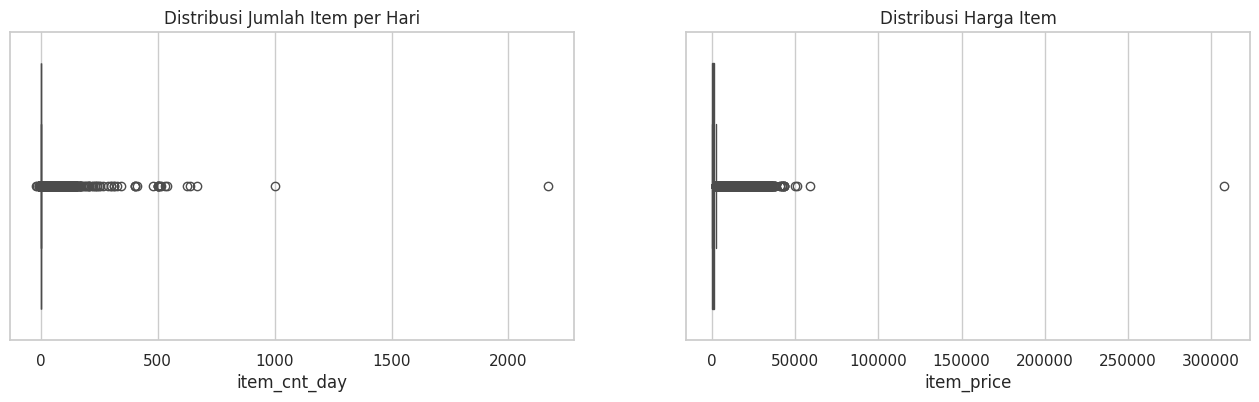

In [ ]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=sales['item_cnt_day'])
plt.title('Distribusi Jumlah Item per Hari')

plt.subplot(1, 2, 2)
sns.boxplot(x=sales['item_price'])
plt.title('Distribusi Harga Item')

plt.show()

# Wawasan: Terlihat jelas adanya outlier (titik data yang ekstrem) pada kedua variabel. Ini membenarkan langkah kita selanjutnya untuk membersihkan outlier.

### Langkah 2: Pra-pemrosesan dan Pembersihan Data

In [ ]:
# 1. Ubah format tanggal
sales['date'] = pd.to_datetime(sales['date'], format='%d.%m.%Y')

# 2. Menghapus outlier berdasarkan visualisasi EDA
sales = sales[sales.item_price < 100000]
sales = sales[sales.item_cnt_day < 1001]

# 3. Mengisi harga median jika ada harga di bawah nol
median = sales[(sales.shop_id==32) & (sales.item_id==2973) & (sales.date_block_num==4) & (sales.item_price>0)].item_price.median()
sales.loc[sales.item_price < 0, 'item_price'] = median

# 4. Membersihkan nama toko yang duplikat
shops.loc[shops.shop_name == 'Сергиев Посад ТЦ "7Я"', 'shop_name'] = 'Сергиев Посад ТЦ \'7Я\''
shops['city'] = shops['shop_name'].str.split(' ').map(lambda x: x[0])
shops.loc[shops.city == '!Якутск', 'city'] = 'Якутск'
shops['city_code'] = pd.factorize(shops['city'])[0]
shops = shops[['shop_id', 'city_code']]

print("Pra-pemrosesan selesai. Outlier telah ditangani dan data toko dibersihkan.")

Pra-pemrosesan selesai. Outlier telah ditangani dan data toko dibersihkan.


### Langkah 3: Agregasi Data ke Tingkat Bulanan

Ini adalah langkah paling penting. Kita akan mengubah data penjualan harian menjadi total penjualan bulanan untuk setiap `shop_id` dan `item_id`.

In [ ]:
# Buat matriks lengkap untuk setiap kombinasi item dan toko per bulan
matrix = []
for i in range(34):
    s = sales[sales.date_block_num == i]
    matrix.append(np.array(list(product([i], s.shop_id.unique(), s.item_id.unique())), dtype='int16'))

matrix = pd.DataFrame(np.vstack(matrix), columns=['date_block_num', 'shop_id', 'item_id'])
matrix.sort_values(['date_block_num', 'shop_id', 'item_id'], inplace=True)

# Agregasi penjualan harian menjadi bulanan
group = sales.groupby(['date_block_num', 'shop_id', 'item_id']).agg({'item_cnt_day': ['sum']})
group.columns = ['item_cnt_month']
group.reset_index(inplace=True)

# Gabungkan matriks dengan data agregasi
matrix = pd.merge(matrix, group, on=['date_block_num', 'shop_id', 'item_id'], how='left')
matrix['item_cnt_month'] = matrix['item_cnt_month'].fillna(0).clip(0, 20).astype(np.float16)

# Gabungkan dengan data test untuk kemudahan feature engineering
test['date_block_num'] = 34
matrix = pd.concat([matrix, test.drop('ID', axis=1)], ignore_index=True, sort=False, keys=['date_block_num', 'shop_id', 'item_id'])
matrix.fillna(0, inplace=True)

# Gabungkan dengan informasi toko dan barang
matrix = pd.merge(matrix, shops, on='shop_id', how='left')
matrix = pd.merge(matrix, items.drop('item_name', axis=1), on='item_id', how='left')
matrix = pd.merge(matrix, item_cats.drop('item_category_name', axis=1), on='item_category_id', how='left')

print("Dataset yang siap untuk feature engineering:")
print(matrix.head())

Dataset yang siap untuk feature engineering:
   date_block_num  shop_id  item_id  item_cnt_month  city_code  \
0               0        0       19             0.0          0   
1               0        0       27             0.0          0   
2               0        0       28             0.0          0   
3               0        0       29             0.0          0   
4               0        0       32             6.0          0   

   item_category_id  
0                40  
1                19  
2                30  
3                23  
4                40  


### Langkah 4: Feature Engineering

Membuat fitur-fitur baru (prediktor) dari data yang ada. Fitur lag (data dari bulan sebelumnya) adalah yang paling penting di sini.

In [ ]:
def lag_feature(df, lags, col):
    tmp = df[['date_block_num', 'shop_id', 'item_id', col]]
    for i in lags:
        shifted = tmp.copy()
        shifted.columns = ['date_block_num', 'shop_id', 'item_id', col + '_lag_' + str(i)]
        shifted['date_block_num'] += i
        df = pd.merge(df, shifted, on=['date_block_num', 'shop_id', 'item_id'], how='left')
    return df

# Membuat fitur lag untuk penjualan bulanan
matrix = lag_feature(matrix, [1, 2, 3, 6, 12], 'item_cnt_month')

# Membuat fitur waktu
matrix['month'] = matrix['date_block_num'] % 12

# Hapus baris dari 12 bulan pertama karena tidak memiliki data lag yang lengkap
matrix.dropna(inplace=True)

print("Dataset setelah feature engineering:")
print(matrix.head())

Dataset setelah feature engineering:
         date_block_num  shop_id  item_id  item_cnt_month  city_code  \
4488710              12        2       27             0.0          1   
4488713              12        2       32             1.0          1   
4488714              12        2       33             1.0          1   
4488715              12        2       34             0.0          1   
4488719              12        2       40             0.0          1   

         item_category_id  item_cnt_month_lag_1  item_cnt_month_lag_2  \
4488710                19                   0.0                   0.0   
4488713                40                   0.0                   0.0   
4488714                37                   1.0                   2.0   
4488715                40                   0.0                   0.0   
4488719                57                   0.0                   0.0   

         item_cnt_month_lag_3  item_cnt_month_lag_6  item_cnt_month_lag_12  \
4488710      

### Langkah 5: Pembagian Data (Train & Test)

Kita akan menggunakan data hingga bulan ke-32 untuk melatih model, dan bulan ke-33 sebagai data validasi/uji untuk membandingkan performa model. Bulan ke-34 adalah data test dari kompetisi.

In [ ]:
  # Tentukan kolom fitur dan target
  features = [col for col in matrix.columns if col not in ['item_cnt_month']]
  target = 'item_cnt_month'

  # Data untuk melatih dan validasi
  X_train = matrix[matrix.date_block_num < 33][features]
  y_train = matrix[matrix.date_block_num < 33][target]
  X_valid = matrix[matrix.date_block_num == 33][features]
  y_valid = matrix[matrix.date_block_num == 33][target]

  # Data test dari kompetisi (untuk prediksi akhir)
  X_test = matrix[matrix.date_block_num == 34][features]

  print('Bentuk data latih (X_train):', X_train.shape)
  print('Bentuk data validasi (X_valid):', X_valid.shape)

Bentuk data latih (X_train): (2018633, 11)
Bentuk data validasi (X_valid): (73185, 11)


### Langkah 6: Pelatihan dan Analisis Model

In [ ]:
# Model 1: Random Forest Regressor
print("Melatih Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_valid).clip(0, 20)
print("Selesai.")

# Model 2: XGBoost Regressor
print("Melatih XGBoost...")
xgb_model = XGBRegressor(
    max_depth=8,
    n_estimators=100,
    min_child_weight=300,
    colsample_bytree=0.8,
    subsample=0.8,
    eta=0.1,
    seed=42,
    eval_metric='rmse'
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_valid).clip(0, 20)
print("Selesai.")

# Model 3: Stacking Ensemble
print("Melatih Stacking Ensemble...")
estimators = [
    ('rf', RandomForestRegressor(n_estimators=25, max_depth=7, random_state=42, n_jobs=-1)),
    ('xgb', XGBRegressor(max_depth=5, n_estimators=50, seed=42, eval_metric='rmse'))
]

stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=LinearRegression(),
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)
stacking_pred = stacking_model.predict(X_valid).clip(0, 20)
print("Selesai.")

Melatih Random Forest...
Selesai.
Melatih XGBoost...
Selesai.
Melatih Stacking Ensemble...
Selesai.


### Langkah 7: Evaluasi dan Perbandingan Model

Tabel Hasil Evaluasi Model:
               Model      RMSE       MAE        R2
1            XGBoost  0.626228  0.292551  0.630097
2  Stacking Ensemble  0.633948  0.296812  0.620921
0      Random Forest  0.642456  0.302956  0.610678


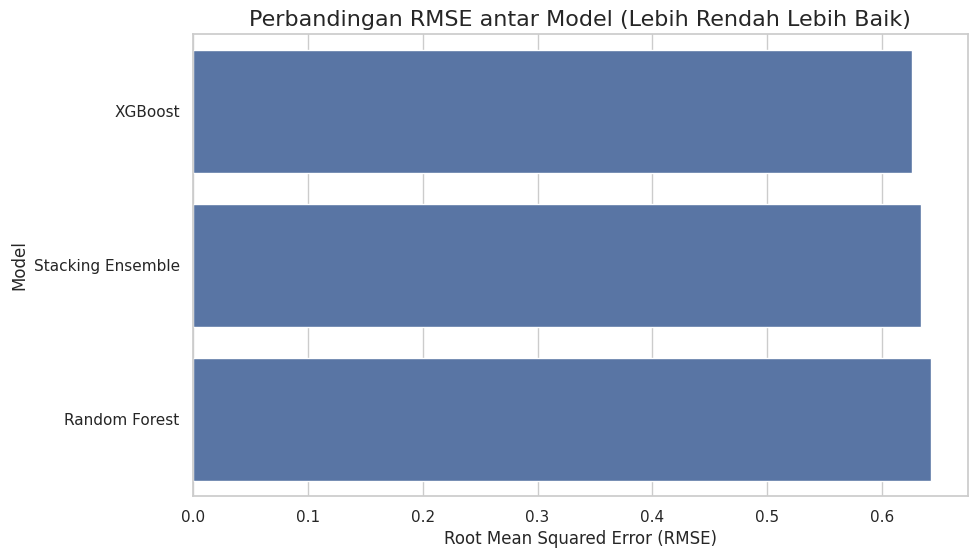

In [ ]:
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': model_name, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

eval_results = [
    evaluate_model(y_valid, rf_pred, 'Random Forest'),
    evaluate_model(y_valid, xgb_pred, 'XGBoost'),
    evaluate_model(y_valid, stacking_pred, 'Stacking Ensemble')
]

eval_df = pd.DataFrame(eval_results).sort_values(by='RMSE')
print("Tabel Hasil Evaluasi Model:")
print(eval_df)

# Visualisasi perbandingan error (RMSE)
plt.figure(figsize=(10, 6))
sns.barplot(x='RMSE', y='Model', data=eval_df, orient='h')
plt.title('Perbandingan RMSE antar Model (Lebih Rendah Lebih Baik)', fontsize=16)
plt.xlabel('Root Mean Squared Error (RMSE)', fontsize=12)
plt.ylabel('Model', fontsize=12)
plt.show()

### Langkah 8: Kesimpulan Analisis

Berdasarkan hasil evaluasi, model dengan nilai **RMSE (Root Mean Squared Error)** terendah adalah model yang terbaik untuk memprediksi penjualan bulanan. RMSE adalah metrik utama dalam kompetisi ini dan sangat cocok untuk mengukur error dalam unit penjualan.

Dari tabel dan grafik di atas, kita dapat memilih model pemenang untuk dijadikan model akhir dalam sistem prediksi stok.